In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

sns.set_theme(style="whitegrid")

data = load_diabetes(as_frame=True)
df = data.frame

df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [11]:
pearson_corr = df.corr(method="pearson")
spearman_corr = df.corr(method="spearman")

print("Pearson correlation:")
print(pearson_corr.round(3))

print("\nSpearman correlation:")
print(spearman_corr.round(3))

Pearson correlation:
          age    sex    bmi     bp     s1     s2     s3     s4     s5     s6  \
age     1.000  0.174  0.185  0.335  0.260  0.219 -0.075  0.204  0.271  0.302   
sex     0.174  1.000  0.088  0.241  0.035  0.143 -0.379  0.332  0.150  0.208   
bmi     0.185  0.088  1.000  0.395  0.250  0.261 -0.367  0.414  0.446  0.389   
bp      0.335  0.241  0.395  1.000  0.242  0.186 -0.179  0.258  0.393  0.390   
s1      0.260  0.035  0.250  0.242  1.000  0.897  0.052  0.542  0.516  0.326   
s2      0.219  0.143  0.261  0.186  0.897  1.000 -0.196  0.660  0.318  0.291   
s3     -0.075 -0.379 -0.367 -0.179  0.052 -0.196  1.000 -0.738 -0.399 -0.274   
s4      0.204  0.332  0.414  0.258  0.542  0.660 -0.738  1.000  0.618  0.417   
s5      0.271  0.150  0.446  0.393  0.516  0.318 -0.399  0.618  1.000  0.465   
s6      0.302  0.208  0.389  0.390  0.326  0.291 -0.274  0.417  0.465  1.000   
target  0.188  0.043  0.586  0.441  0.212  0.174 -0.395  0.430  0.566  0.382   

        target  
a

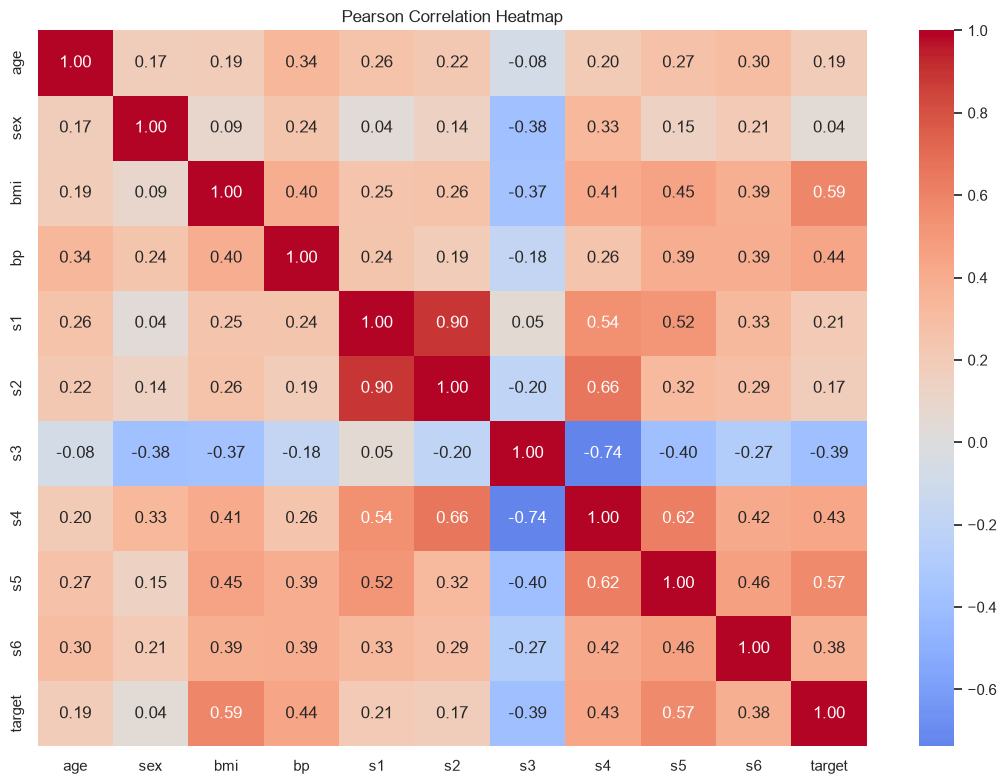

In [12]:
plt.figure(figsize=(11, 8))
sns.heatmap(
    pearson_corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)
plt.title("Pearson Correlation Heatmap")
plt.tight_layout()
plt.show()

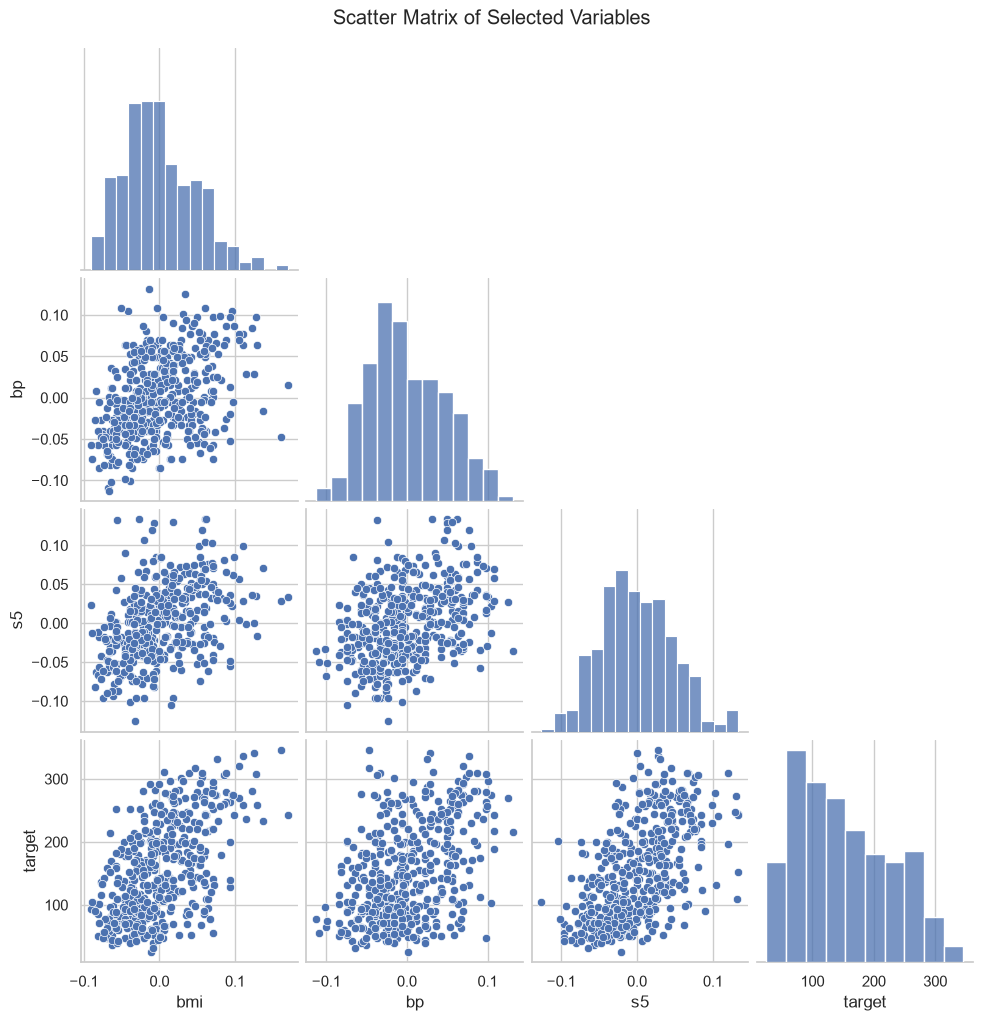

In [13]:
selected_columns = ["bmi", "bp", "s5", "target"]

sns.pairplot(
    df[selected_columns],
    diag_kind="hist",
    corner=True
)
plt.suptitle("Scatter Matrix of Selected Variables", y=1.02)
plt.show()


In [14]:
X = df[["bmi"]]
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Intercept:", round(model.intercept_, 3))
print("Coefficient:", round(model.coef_[0], 3))
print("R²:", round(r2_score(y_test, y_pred), 3))
print("MAE:", round(mean_absolute_error(y_test, y_pred), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred)), 3))

Intercept: 152.003
Coefficient: 998.578
R²: 0.233
MAE: 52.26
RMSE: 63.732


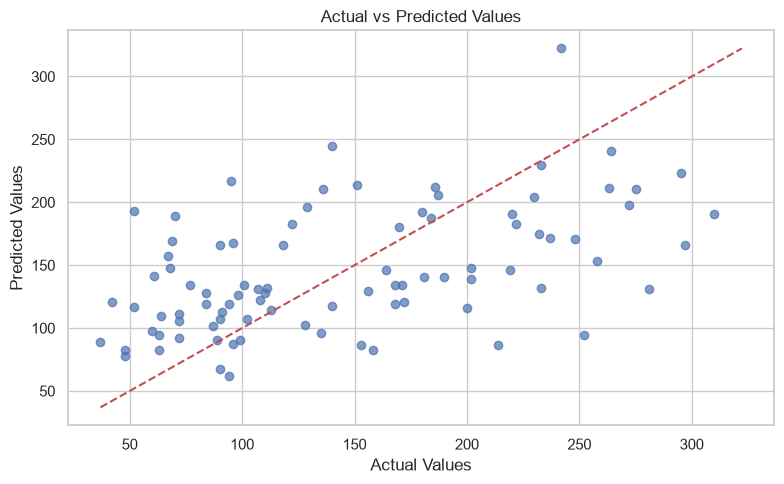

In [15]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, alpha=0.7)

limits = [
    min(y_test.min(), y_pred.min()),
    max(y_test.max(), y_pred.max())
]
plt.plot(limits, limits, "r--")

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted Values")
plt.tight_layout()
plt.show()

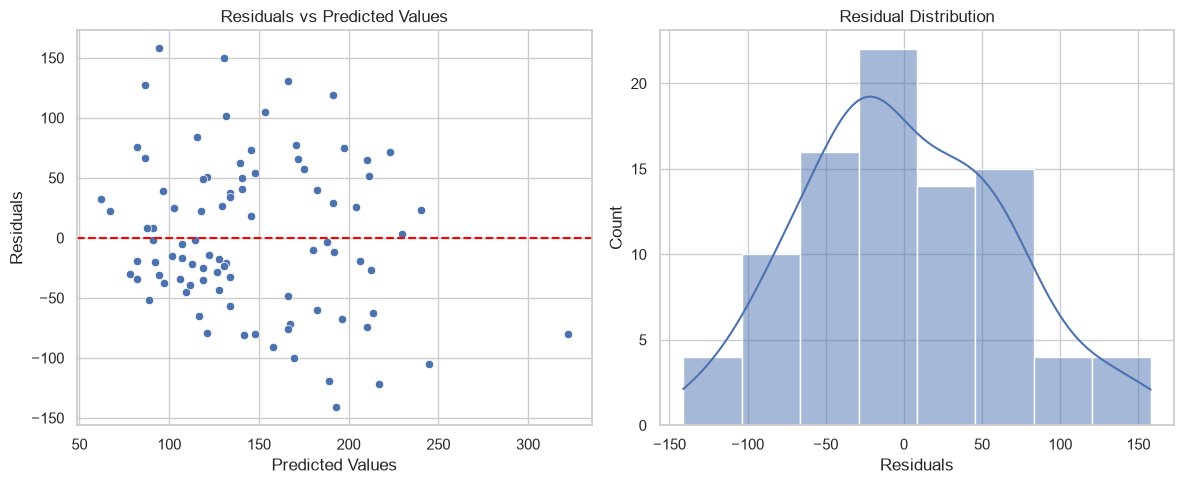

In [16]:
residuals = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.scatterplot(x=y_pred, y=residuals, ax=axes[0])
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_title("Residuals vs Predicted Values")
axes[0].set_xlabel("Predicted Values")
axes[0].set_ylabel("Residuals")

sns.histplot(residuals, kde=True, ax=axes[1])
axes[1].set_title("Residual Distribution")
axes[1].set_xlabel("Residuals")

plt.tight_layout()
plt.show()

In [17]:
results = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": y_pred,
    "Residual": residuals.to_numpy()
})

print(results.head(10))

   Actual   Predicted    Residual
0   219.0  145.806227   73.193773
1    70.0  188.857390 -118.857390
2   202.0  147.958785   54.041215
3   230.0  203.925298   26.074702
4   111.0  131.814599  -20.814599
5    84.0  127.509482  -43.509482
6   242.0  322.315998  -80.315998
7   272.0  197.467623   74.532377
8    94.0   61.856458   32.143542
9    96.0  167.331809  -71.331809


# Week 4 — Day 3: Regression Analysis

## Objective
Measure relationships between variables using Pearson and Spearman
correlation and build a simple linear regression model.

## Dataset
The scikit-learn diabetes dataset is used for demonstration.
BMI is the independent variable and the target is the dependent variable.

## Correlation
- Pearson measures the strength and direction of a linear relationship.
- Spearman measures the strength and direction of a monotonic relationship
  using ranks.
- Correlation does not prove causation.

## Regression Metrics
- R² measures the proportion of target variance explained by the model.
- MAE is the average absolute prediction error.
- RMSE penalizes larger prediction errors more strongly.

## Residual Analysis
Residuals are actual values minus predicted values.
A random pattern around zero is desirable. Curvature, changing spread,
or strong departures from normality may indicate model issues.

## Business Application
Indian retail companies can use regression to study how advertising spend,
prices, and promotions relate to sales. Correlation helps identify
relationships, while regression estimates outcomes. Neither alone
establishes causation.

## Conclusion
The notebook compares correlation methods, visualizes relationships,
trains a linear regression model, evaluates predictions, and inspects
residuals. Results should be interpreted using the printed metrics
and actual plots.